# 12 · Knowledge assistant: retrieval-augmented answers (RAG)

**Phase 7 · RAG.** Operators ask questions such as *"What do we do when a robot overheats?"*. The
answer is in the warehouse documents (6 PDFs: operations manual, robot manual, safety rules,
maintenance guide, SOPs, inventory policies), not in any model's memory. **Retrieval-augmented
generation** answers in two steps:

1. **Retrieve**: find the few passages that contain the answer (search over chunks of the PDFs).
2. **Answer**: write the answer *from those passages only*, citing them, or say the documents do
   not cover the question.

| Part | Options compared here | Code |
|---|---|---|
| Chunking | one chunk per numbered section · fixed windows of 120 words · of 40 words | `ai/rag/ingest.py` |
| Retrieval | BM25 (keywords) · dense (MiniLM embeddings) · hybrid (both, Reciprocal Rank Fusion) · hybrid + cross-encoder rerank | `ai/rag/retriever.py`, `ai/embeddings/embedder.py` |
| Not covered | minimum retrieval score, chosen on development questions | `ai/rag/pipeline.py` |
| Answer | extractive (sentences / whole section from the documents) · optionally Claude | `ai/rag/generator.py` |

**Evaluation data.** 94 questions with reference answers and the sections that answer them
(`data/processed/rag/questions.jsonl`): 62 factual, 19 procedural, 7 multi-hop (need two or three
sections), 6 unanswerable (the documents do not say). They are split, stratified by type, into
**development** (38: every choice is made here) and **test** (56: scored once at the end).

In [1]:
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from sentence_transformers import CrossEncoder  # noqa: E402

from ai.embeddings.embedder import Embedder  # noqa: E402
from ai.rag.evaluation import (  # noqa: E402
    answer_scores,
    load_questions,
    retrieval_scores,
    split_questions,
)  # fmt: skip
from ai.rag.ingest import load_chunks  # noqa: E402
from ai.rag.pipeline import KnowledgeBase, Settings  # noqa: E402
from ai.rag.retriever import Retriever  # noqa: E402

torch.set_num_threads(4)
MODELS = ROOT / "models"
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

defaults = Settings()
embedder = Embedder(defaults.embedder)  # all-MiniLM-L6-v2: 22 M parameters, 384 numbers per text
reranker = CrossEncoder(defaults.reranker, device="cpu")  # ms-marco-MiniLM-L6-v2 cross-encoder
print("embedding size:", embedder.dim)

H:\ai-warehouse-platform\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/cross-encoder/ms-marco-MiniLM-L6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'cross-encoder/ms-marco-MiniLM-L6-v2'.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2180.77it/s]


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/all-MiniLM-L6-v2'.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2276.98it/s]

embedding size: 384


## 1. From PDFs to chunks

Text is extracted from the PDFs with `pypdf`; bullets and wrapped lines are cleaned. A **chunk**
is the unit that is searched and handed to the answer writer. Each chunk is embedded together
with its document title and heading (a *contextual chunk header*), so a short section such as
"SOP-04 ... 1. Let the robot finish its order" still carries the word *overheating*.

In [2]:
CHUNKINGS = {
    "section": {"strategy": "section"},
    "fixed 120 words": {"strategy": "fixed", "size": 120, "overlap": 30},
    "fixed 40 words": {"strategy": "fixed", "size": 40, "overlap": 10},
}
chunk_sets = {name: load_chunks(**opts) for name, opts in CHUNKINGS.items()}
pd.DataFrame(
    {
        name: {
            "chunks": len(ch),
            "mean words": round(np.mean([len(c.text.split()) for c in ch])),
            "max words": max(len(c.text.split()) for c in ch),
            "sections per chunk": round(np.mean([len(c.sections) for c in ch]), 2),
        }
        for name, ch in chunk_sets.items()
    }
).T

,chunks,mean words,max words,sections per chunk
section,120.0,40.0,174.0,1.00
fixed 120 words,56.0,113.0,120.0,4.32
fixed 40 words,163.0,39.0,40.0,2.18


In [3]:
questions = load_questions()
split = split_questions(questions, dev_share=0.4, seed=0)
dev, test = split["dev"], split["test"]
pd.DataFrame(
    {part: pd.Series([q["type"] for q in qs]).value_counts() for part, qs in split.items()}
).fillna(0).astype(int)

,dev,test
factual,25,37
procedural,8,11
multi_hop,3,4
unanswerable,2,4


## 2. Which chunking and which retriever? (development questions)

Scores over the answerable questions, top **k = 3** passages (what the answer writer reads):

* **hit@3**: a right section is among the 3; **all@3**: all needed sections are (multi-hop);
* **MRR**: 1 / rank of the first right passage; **cite@1**: the first passage, which is the main
  citation, is a right section;
* **words read**: text the answer writer must read (longer chunks find more but cite less exactly
  and cost more if an LLM reads them).

**Rule fixed before looking at the results:** the answer needs the right text among the 3
passages *and* a correct citation, so pick the highest **hit@3 + cite@1**; ties go to the higher
MRR, then to fewer words read.

In [4]:
vectors = {name: embedder.encode([c.for_embedding() for c in ch]) for name, ch in chunk_sets.items()}
MODES = ["bm25", "dense", "hybrid", "rerank"]
retrievers, rows = {}, []
for cname, ch in chunk_sets.items():
    for mode in MODES:
        r = Retriever(ch, embedder, mode, reranker, vectors=vectors[cname], candidates=defaults.candidates)
        retrievers[(cname, mode)] = r
        s = retrieval_scores(lambda q, r=r: r.search(q, k=3), dev, k=3)
        rows.append({"chunking": cname, "retriever": mode, **s})
grid = pd.DataFrame(rows)
grid["hit + cite"] = grid["hit@3"] + grid["cite@1"]
grid = grid.sort_values(["hit + cite", "MRR", "words_read"], ascending=[False, False, True])
grid[["chunking", "retriever", "hit@3", "all@3", "MRR", "cite@1", "words_read", "ms_per_question"]]

,chunking,retriever,hit@3,all@3,MRR,cite@1,words_read,ms_per_question
3,section,rerank,0.944,0.889,0.870,0.806,172,779.0
2,section,hybrid,0.944,0.889,0.787,0.667,160,34.6
0,section,bm25,0.861,0.750,0.676,0.556,158,24.4
1,section,dense,0.833,0.750,0.685,0.556,170,22.8
11,fixed 40 words,rerank,0.917,0.833,0.852,0.444,119,382.4
10,fixed 40 words,hybrid,0.861,0.750,0.759,0.389,119,28.2
7,fixed 120 words,rerank,0.972,0.917,0.940,0.222,354,815.1
8,fixed 40 words,bm25,0.889,0.806,0.704,0.278,118,24.1
9,fixed 40 words,dense,0.778,0.639,0.620,0.361,119,24.8
6,fixed 120 words,hybrid,0.917,0.806,0.824,0.111,354,19.0


chosen on development: section chunks, rerank retrieval


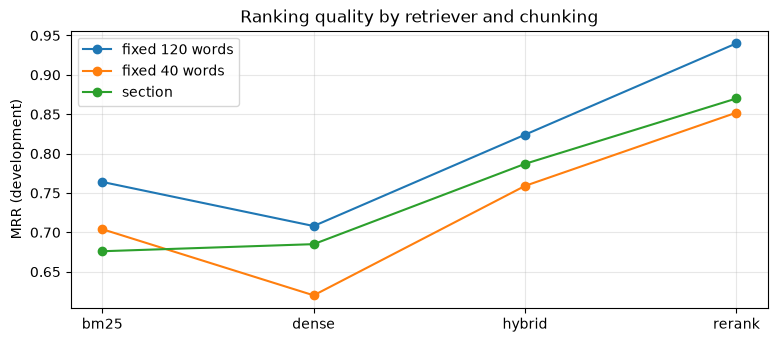

In [5]:
best = grid.iloc[0]
chosen_chunking, chosen_retriever = best["chunking"], best["retriever"]
print(f"chosen on development: {chosen_chunking} chunks, {chosen_retriever} retrieval")

fig, ax = plt.subplots(figsize=(9, 3.6))
for cname, part in grid.groupby("chunking"):
    part = part.set_index("retriever").loc[MODES]
    ax.plot(MODES, part["MRR"], marker="o", label=f"{cname}")
ax.set_ylabel("MRR (development)")
ax.set_title("Ranking quality by retriever and chunking")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3. When to say "not covered"

Six questions ask for things the documents do not contain (prices, Wi-Fi passwords, the robot's
weight ...). A system that always answers would quote the closest passage as if it were the
answer. The assistant therefore answers only when the best passage scores above a **threshold**.

The development set holds just 2 unanswerable questions, too few to tune on. The threshold is set
from the **answerable** development questions instead: the 5th percentile of their best scores,
i.e. it is allowed to wrongly refuse about 1 answerable question in 20. Test shows what it catches.

threshold (score of the best passage) = 0.663


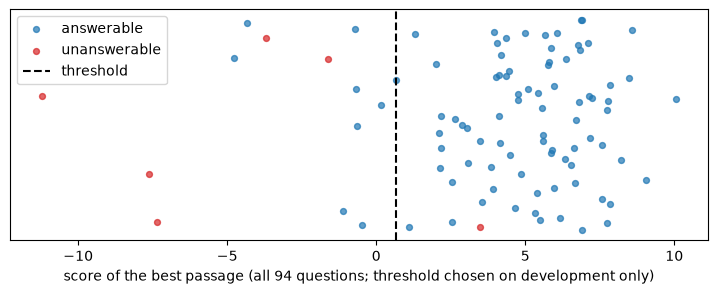

In [6]:
chosen = retrievers[(chosen_chunking, chosen_retriever)]
top_score = {q["id"]: chosen.search(q["question"], k=1)[0].score for q in questions}
dev_answerable = [top_score[q["id"]] for q in dev if q["sources"]]
threshold = float(np.percentile(dev_answerable, 5))
print(f"threshold (score of the best passage) = {threshold:.3f}")

fig, ax = plt.subplots(figsize=(9, 3))
for label, qs, color in [("answerable", [q for q in questions if q["sources"]], "tab:blue"),
                         ("unanswerable", [q for q in questions if not q["sources"]], "tab:red")]:
    ax.scatter([top_score[q["id"]] for q in qs], np.random.default_rng(0).uniform(0, 1, len(qs)),
               s=18, color=color, label=label, alpha=0.7)
ax.axvline(threshold, color="black", ls="--", label="threshold")
ax.set_yticks([])
ax.set_xlabel("score of the best passage (all 94 questions; threshold chosen on development only)")
ax.legend(loc="upper left")
plt.show()

## 4. Test: retrieval, the not-covered decision and the answers

Scored once, with everything chosen above. For context the simplest setup (dense search over
section chunks, no reranker) is scored too.

**Answers** are scored against the reference answers with **token F1** (word overlap, as in the
SQuAD benchmark: a rough measure, since a correct answer in other words scores low) and by
whether they **cite a right section**. Two extractive styles are compared: the 3 best-matching
sentences of the retrieved sections, or the whole best section (up to 120 words). The style used
live is chosen on the development questions.

In [7]:
baseline = retrievers[("section", "dense")]
test_retrieval = pd.DataFrame(
    {
        f"chosen: {chosen_chunking} + {chosen_retriever}": retrieval_scores(lambda q: chosen.search(q, k=3), test, k=3),
        "simple: section + dense": retrieval_scores(lambda q: baseline.search(q, k=3), test, k=3),
    }
).T
test_retrieval

,hit@3,all@3,MRR,cite@1,words_read,hit@3 factual,hit@3 multi_hop,hit@3 procedural,ms_per_question,questions
chosen: section + rerank,0.962,0.846,0.910,0.865,163.0,0.973,1.0,0.909,572.1,52.0
simple: section + dense,0.981,0.846,0.869,0.769,165.0,0.973,1.0,1.000,17.7,52.0


In [8]:
settings = Settings(chunking=chosen_chunking, retriever=chosen_retriever, k=3,
                    candidates=defaults.candidates, threshold=round(threshold, 3))
answers, dev_answers, kbs = {}, {}, {}
for style in ["sentences", "section"]:
    settings.answer_style = style
    kb = KnowledgeBase(chunk_sets[chosen_chunking], chosen, Settings(**asdict(settings)))
    kbs[style] = kb
    dev_answers[style] = answer_scores(kb.ask, dev)  # the style is chosen here, on development
    answers[f"extractive: {style}"] = answer_scores(kb.ask, test)
best_style = max(dev_answers, key=lambda s: dev_answers[s]["answer_token_F1"] or 0)
print("answer style chosen on development (token F1):", best_style,
      {s: v["answer_token_F1"] for s, v in dev_answers.items()})
answer_table = pd.DataFrame(answers).T
answer_table

answer style chosen on development (token F1): section {'sentences': 0.331, 'section': 0.451}


,covered_decision_right,answer_token_F1,cites_a_right_section,cited_source_recall,ms_per_question,questions
extractive: sentences,0.857,0.316,0.867,0.77,918.7,56.0
extractive: section,0.857,0.475,0.889,0.80,966.0,56.0


In [9]:
unanswerable_test = [q for q in test if not q["sources"]]
refused = [q["question"] for q in unanswerable_test if top_score[q["id"]] < threshold]
wrongly_refused = [q["question"] for q in test if q["sources"] and top_score[q["id"]] < threshold]
print(f"unanswerable test questions refused: {len(refused)} of {len(unanswerable_test)}")
for text in refused:
    print("  refused  :", text)
for q in unanswerable_test:
    if q["question"] not in refused:
        print("  answered :", q["question"], f"(score {top_score[q['id']]:.2f})")
print(f"answerable test questions wrongly refused: {len(wrongly_refused)} of {sum(1 for q in test if q['sources'])}")
for text in wrongly_refused:
    print("  ", text)

unanswerable test questions refused: 3 of 4
  refused  : What is the maximum payload of a robot in kilograms?
  refused  : Who is the shift lead on Sunday?
  refused  : Which courier collects parcels from the packing stations?
  answered : How much does an AMR-500 robot weigh? (score 3.49)
answerable test questions wrongly refused: 7 of 52
   What are the stages of an order's life cycle?
   What does the location code B-14-50 mean?
   How accurate is the temperature sensor?
   How long does a robot spend picking and unloading?
   How is throughput defined?
   How should we prepare for Black Friday?
   A robot's battery dropped from 64 % to 41 % in one step. What is it and what next?


## 5. Where retrieval still fails (test)

In [10]:
misses = []
for q in test:
    if not q["sources"]:
        continue
    hits = chosen.search(q["question"], k=3)
    wanted = {s.split("#")[1] for s in q["sources"]}
    got = [h.chunk.section_id for h in hits]
    if not wanted & {s for h in hits for s in h.chunk.sections}:
        misses.append({"type": q["type"], "question": q["question"], "needed": sorted(wanted), "retrieved": got})
print(f"{len(misses)} of {sum(1 for q in test if q['sources'])} answerable test questions without a right passage in the top 3")
pd.DataFrame(misses)

2 of 52 answerable test questions without a right passage in the top 3


,type,question,needed,retrieved
0,factual,How long does a robot spend picking and unloading?,[WM-5.5],"[INV-3.3, RM-3, WM-6.2]"
1,procedural,A robot is slow although its route is free. What should I check first?,[MG-3.2],"[MG-3.1, SOP-09, MG-1.3]"


## 6. Example answers (extractive, best style)

In [11]:
kb = kbs[best_style]
for text in [
    "What do we do when a robot overheats?",
    "How many charging bays are there?",
    "Can a person walk into a closed aisle?",
    "When is a product reordered?",
    "What is the Wi-Fi password for the robot network?",
]:
    out = kb.ask(text)
    print(f"Q: {text}\nA: {out['answer']}\n   sources: {[s['section_id'] for s in out['sources']]} · {out['ms']} ms\n")

Q: What do we do when a robot overheats?
A: Trigger: motor temperature above 60 C, or an overheating fault. Let the robot finish its current order: above 60 C it throttles to half speed automatically. If its temperature keeps rising above 70 C, pause it at the next safe stop (a parking bay or a wide highway lane, never a narrow aisle) and reassign its order. Do not assign new orders to the robot until its temperature is below 55 C. Resume it after cooling; if it overheats twice in one shift, send it for inspection (MG-6). [SOP-04]
   sources: ['SOP-04', 'MG-6.2', 'RM-5.3'] · 812 ms



Q: How many charging bays are there?
A: Each charger has three bays. If every bay is taken, a robot that only wants a top-up stays parked and tries again later; a low-battery robot keeps waiting for the nearest free bay. [RM-4.4]
   sources: ['RM-4.4', 'WM-2.6', 'SAF-3.4'] · 722 ms



Q: Can a person walk into a closed aisle?
A: An operator may close an aisle on request ("avoid Aisle 7"). Closing an aisle is only allowed when no robot or person is inside it and no robot is about to pick from it; otherwise pause the robots concerned first (SOP-05). [SAF-3.6]
   sources: ['SAF-3.6', 'SAF-3.2', 'WM-4.3'] · 846 ms



Q: When is a product reordered?
A: Reorder point: when a bay's stock falls below 10 units, a replenishment order is raised automatically (one open replenishment per bay at a time). [INV-3.1]
   sources: ['INV-3.1', 'INV-2.3', 'INV-4.1'] · 374 ms



Q: What is the Wi-Fi password for the robot network?
A: The warehouse documents do not cover this. Ask the shift lead, or rephrase the question.
   sources: ['RM-7.3', 'RM-7.1', 'WM-7.2'] · 786 ms



## 7. Optional: answers written by Claude

An LLM can combine several passages and phrase a procedure clearly; the extractive writer can only
quote. This cell runs only when an Anthropic API key is configured (`LLM_PROVIDER=anthropic`,
`LLM_API_KEY=...` in `.env`): it costs one API call per test question (56). The same retrieval,
threshold and scoring are used, so the difference is the writer alone.

In [12]:
llm_scores = None
if os.environ.get("LLM_PROVIDER", "").lower() == "anthropic":
    from ai.rag.generator import ClaudeGenerator

    kb_llm = KnowledgeBase(chunk_sets[chosen_chunking], chosen, Settings(**asdict(settings)),
                           generator=ClaudeGenerator(api_key=os.environ.get("LLM_API_KEY") or None))
    llm_scores = answer_scores(kb_llm.ask, test)
    display(pd.DataFrame({**answers, "Claude": llm_scores}).T)
else:
    print("Skipped: no LLM configured. Extractive answers are the default (free, offline, cannot invent facts).")

Skipped: no LLM configured. Extractive answers are the default (free, offline, cannot invent facts).


## 8. Save the settings and the report

The backend (`apps/backend/app/services/knowledge.py`) reads `models/rag_v1.json` for the chosen
chunking, retriever, k, threshold and answer style. The documents are re-read from the PDFs when
the backend starts (120 chunks take about a second to embed), or loaded into PostgreSQL with
pgvector by `scripts/ingest_documents.py --db`.

In [13]:
settings.answer_style = best_style
report = {
    "model": "rag_v1",
    "settings": asdict(settings),
    "documents": 6,
    "chunks": {name: len(ch) for name, ch in chunk_sets.items()},
    "split": {"dev": len(dev), "test": len(test)},
    "development_grid": grid.drop(columns=["hit + cite"]).to_dict("records"),
    "test_retrieval": test_retrieval.reset_index(names="setup").to_dict("records"),
    "test_answers": answers if llm_scores is None else {**answers, "Claude": llm_scores},
    "not_covered": {
        "threshold": round(threshold, 3),
        "unanswerable_refused": f"{len(refused)} of {len(unanswerable_test)}",
        "answerable_wrongly_refused": f"{len(wrongly_refused)} of {sum(1 for q in test if q['sources'])}",
    },
    "test_misses": misses,
}
(MODELS / "rag_v1.json").write_text(json.dumps(report, indent=2, default=float), encoding="utf-8")
print("Saved models/rag_v1.json:", report["settings"])

Saved models/rag_v1.json: {'chunking': 'section', 'retriever': 'rerank', 'k': 3, 'candidates': 10, 'threshold': 0.663, 'answer_style': 'section', 'embedder': 'sentence-transformers/all-MiniLM-L6-v2', 'reranker': 'cross-encoder/ms-marco-MiniLM-L6-v2'}


## 9. Conclusions

| Test (56 questions, never used for a choice) | Result |
|---|---|
| A right passage among the 3 retrieved (hit@3) | **0.962** (50 of 52 answerable) |
| Ranking (MRR) · first passage cites a right section (cite@1) | **0.910** · **0.865** (simple dense search: 0.869 · 0.769) |
| Unanswerable questions refused | 3 of 4 |
| Answerable questions wrongly refused | 7 of 52 (13 %) |
| Answer cites a right section · word overlap with the reference (token F1) | 0.889 · 0.475 |
| Time per question on a laptop CPU | ~0.6-1 s (the cross-encoder; dense search alone: 20 ms) |

* **Chunk by section, not by window.** 120-word windows find the right text slightly more often
  (they are 3× longer), but the first passage is a right citation only 22 % of the time on
  development, against 81 % for sections. For a system that must say *where* an answer comes from,
  the document's own structure is the better unit.
* **The reranker earns its cost.** Hybrid retrieval puts the right section in the top 3 as often as
  the cross-encoder, but the cross-encoder puts it **first** far more often (cite@1 0.81 vs 0.67 on
  development), which is what the answer and its citation rely on.
* **"Not covered" is the hardest part.** Retrieval scores overlap: "How much does an AMR-500
  weigh?" looks like a real manual question (score 3.5) and is answered from the nearest section,
  while 7 answerable questions score below the threshold. The threshold was fixed on development
  data and is not retuned on test. In the app, the closest passages are shown even when the
  assistant refuses, so the operator can still read them.
* **Extractive answers are faithful but rigid**: every word is from the documents and the citation
  is exact, but the writer cannot combine two sections or rephrase. Whole sections beat 3 loose
  sentences (token F1 0.475 vs 0.316) because procedures stay together. An LLM writer (section 7,
  optional) is the natural next step; it reads the same 3 passages under the same threshold.
* **Limits:** 94 questions are few (one question = 1.9 points on test); the documents were written
  for this simulator; real manuals have scanned pages, figures and contradictions.